(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.0000

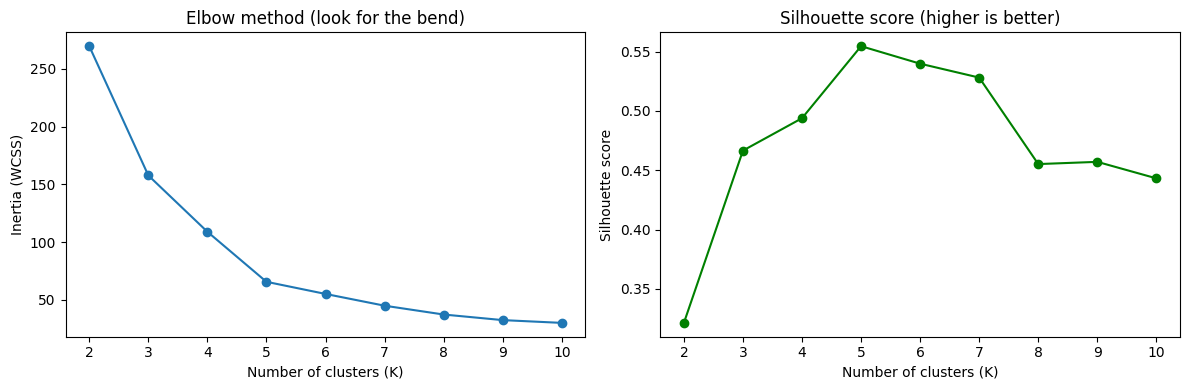


Customers per cluster:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Final silhouette score: 0.555


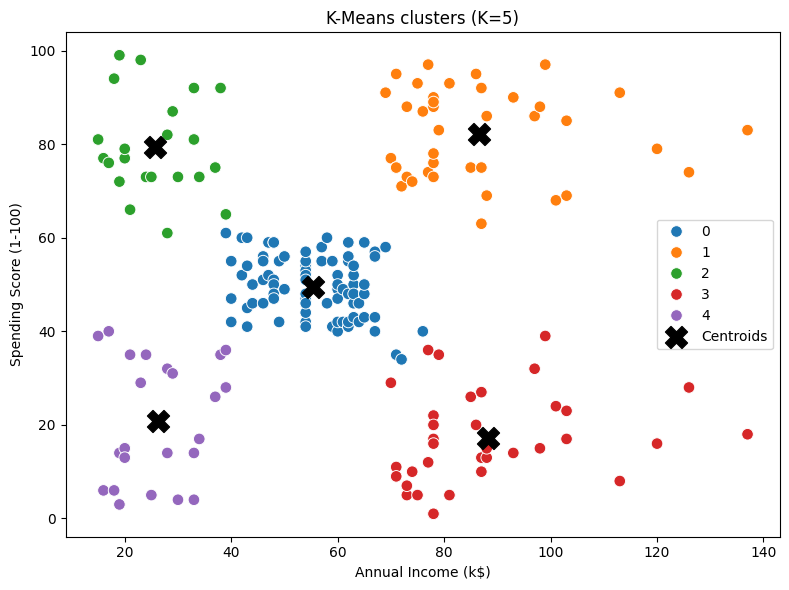

In [11]:
# 0. IMPORTS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# 1. LOAD + INSPECT

df = pd.read_csv("Mall_Customers.csv")

print(df.shape)
print(df.head())
print(df.describe())
print("Missing values:", df.isnull().sum().sum())

# 2. CHOOSE FEATURES AND SCALE THEM

features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. ELBOW METHOD (+ silhouette score) TO FIND THE BEST K

k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))
    print(f"K={k:2d}  inertia={km.inertia_:8.2f}  silhouette={silhouettes[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(list(k_values), inertias, marker="o")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method (look for the bend)")

ax[1].plot(list(k_values), silhouettes, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score (higher is better)")

plt.tight_layout()
plt.show()


# 4. FIT THE FINAL MODEL

best_k = 5   # <- choose from the elbow / silhouette plots

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"\nCustomers per cluster:\n", df["Cluster"].value_counts().sort_index())

print(f"Final silhouette score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))

# 5. VISUALIZE THE CLUSTERS

# Centroids were learned in scaled space, so convert them back to real units

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df, x=features[0], y=features[1],
    hue="Cluster", palette="tab10", s=70
)

plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="X", s=250, c="black", label="Centroids"
)

plt.title(f"K-Means clusters (K={best_k})")
plt.legend()
plt.tight_layout()
plt.show()

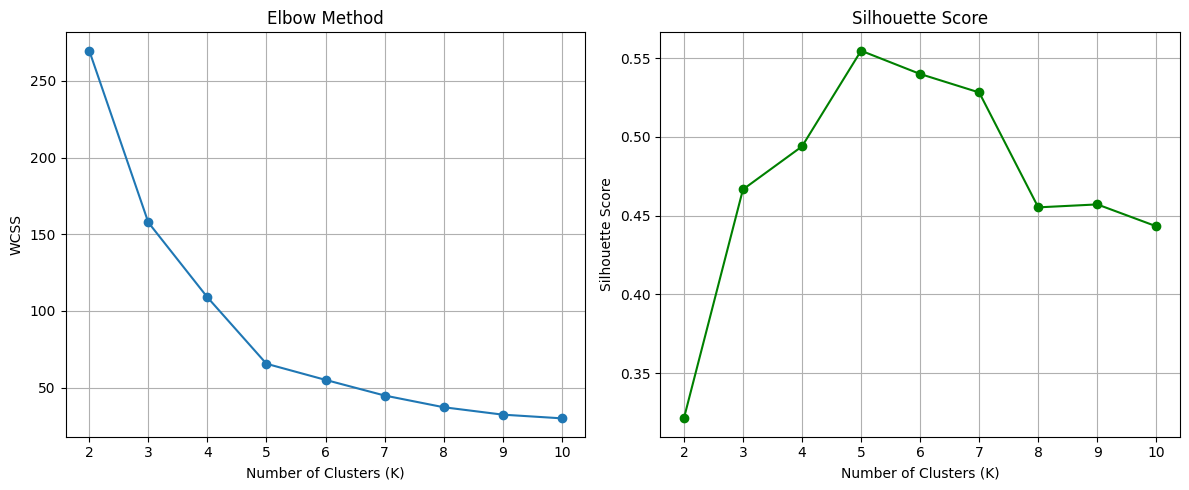

Best number of clusters: 5


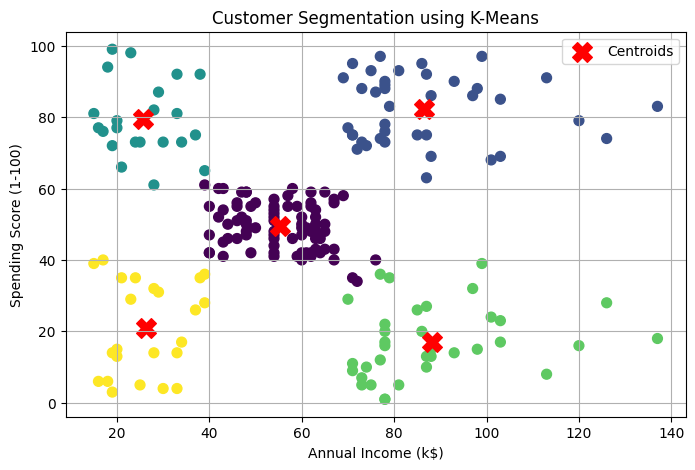

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("Mall_Customers.csv")

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
sil_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(2, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), sil_scores, marker='o', color='green')
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid()

plt.tight_layout()
plt.show()

best_k = range(2, 11)[sil_scores.index(max(sil_scores))]
print("Best number of clusters:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df['Cluster'], cmap='viridis', s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.grid()
plt.show()